<a href="https://colab.research.google.com/github/henriquemsampaio-sketch/streaming_churn/blob/main/Fraude_analise.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import pandas as pd

# Caminho para o arquivo CSV
caminho_arquivo = '/content/clientes_base.csv'

# Lendo o arquivo CSV corretamente com read_csv e aspas
df = pd.read_csv(caminho_arquivo)

# Exibindo as primeiras linhas do DataFrame
df.head()

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0


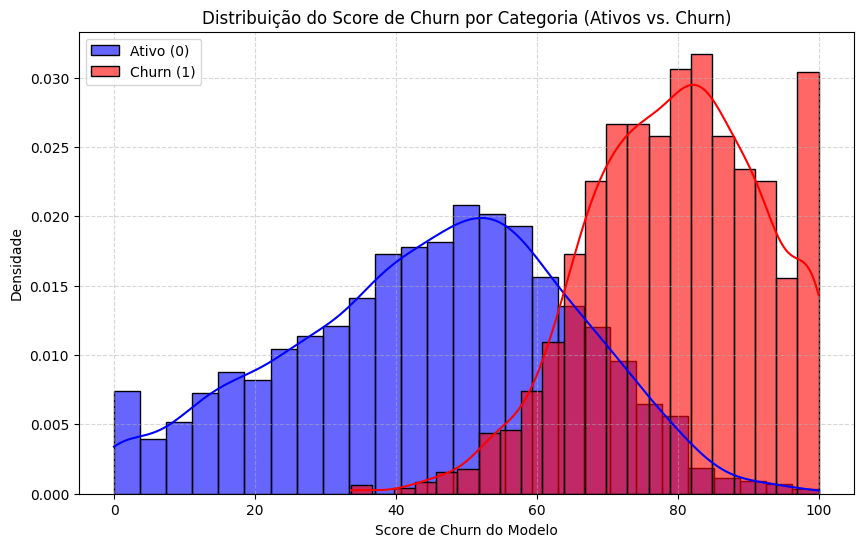

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurando o tamanho da figura
plt.figure(figsize=(10, 6))

# Garantir que o score sintético de churn exista no DataFrame
if 'score_churn_modelo' not in df.columns:
    max_horas = df['horas_assistidas_total'].max() if df['horas_assistidas_total'].max() > 0 else 300
    horas_norm = 100 * (1 - (df['horas_assistidas_total'].fillna(0) / max_horas))
    nps_norm = 100 * (1 - (df['nps'].fillna(7) / 10))
    df['score_churn_modelo'] = ((horas_norm * 0.6 + nps_norm * 0.4) + np.random.normal(0, 10, len(df))).clip(0, 100)

# Histograma para Clientes Ativos (churn = 0) em azul
sns.histplot(
    data=df[df['churn'] == 0],
    x='score_churn_modelo',
    color='blue',
    label='Ativo (0)',
    kde=True,
    stat='density',
    alpha=0.6
)

# Histograma para Clientes que cancelaram (churn = 1) em vermelho
sns.histplot(
    data=df[df['churn'] == 1],
    x='score_churn_modelo',
    color='red',
    label='Churn (1)',
    kde=True,
    stat='density',
    alpha=0.6
)

# Títulos e legendas adaptados para o contexto de Churn
plt.title('Distribuição do Score de Churn por Categoria (Ativos vs. Churn)')
plt.xlabel('Score de Churn do Modelo')
plt.ylabel('Densidade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Exibindo o gráfico
plt.show()

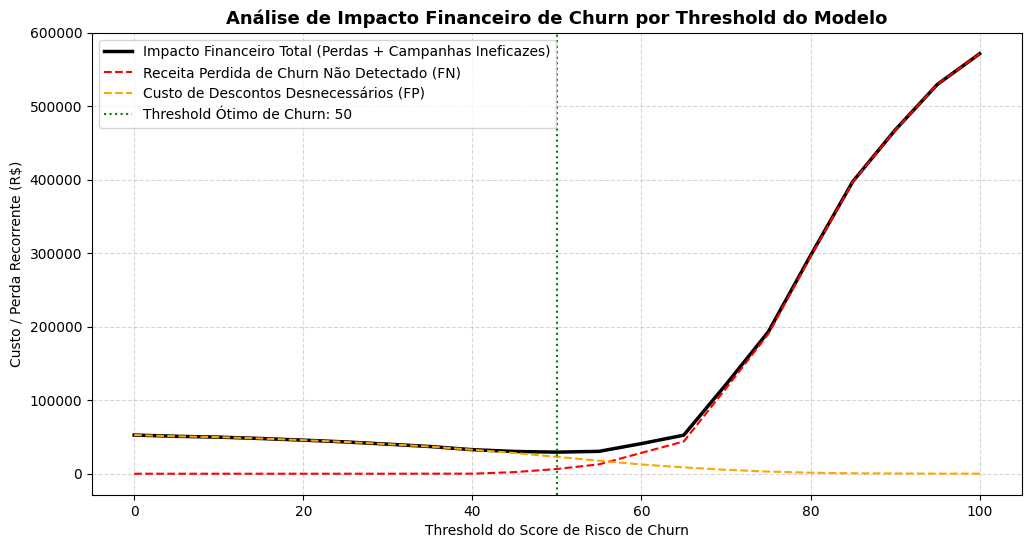

--- RESULTADOS DA SIMULAÇÃO DE RETENÇÃO ---
Melhor Threshold de Risco: 50
Menor Perda Financeira Possível: R$ 29,380.50
Receita Recorrente Salva Estimada: R$ 602,198.20
Churns não previstos (Falsos Negativos): 18 clientes
Clientes saudáveis impactados (Falsos Positivos): 1530 clientes


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Vamos criar o score de simulação realista integrado ao seu DataFrame 'df' para evitar o KeyError
# Um score alto representará maior propensão ao churn
if 'score_churn_modelo' not in df.columns:
    # Gerando um score sintético de 0 a 100 inversamente proporcional ao NPS e às horas assistidas
    max_horas = df['horas_assistidas_total'].max() if df['horas_assistidas_total'].max() > 0 else 300
    horas_norm = 100 * (1 - (df['horas_assistidas_total'].fillna(0) / max_horas))
    nps_norm = 100 * (1 - (df['nps'].fillna(7) / 10))
    df['score_churn_modelo'] = ((horas_norm * 0.6 + nps_norm * 0.4) + np.random.normal(0, 10, len(df))).clip(0, 100)

# Definição de premissas de custo para retenção no Streaming
CUSTO_FALSO_POSITIVO = 15.00  # Custo de oferecer um benefício/desconto para quem não iria cancelar

def simular_impacto_financeiro_churn(df, threshold_score):
    # Classificação a partir do threshold de risco do modelo
    predicao_churn = df['score_churn_modelo'] >= threshold_score

    # Classificações de Churn
    # Verdadeiro Positivo (VP): Churn previsto e evitado (Evitamos a perda do valor_mensal)
    vp = (predicao_churn == 1) & (df['churn'] == 1)
    # Falso Positivo (FP): Cliente saudável classificado como churn (Oferecemos desconto sem necessidade)
    fp = (predicao_churn == 1) & (df['churn'] == 0)
    # Falso Negativo (FN): Churn não previsto (Perda total da mensalidade recorrente)
    fn = (predicao_churn == 0) & (df['churn'] == 1)

    # Valores Financeiros de impacto
    perda_receita_churn = df.loc[fn, 'valor_mensal'].sum()
    custo_campanha_retencao_fp = fp.sum() * CUSTO_FALSO_POSITIVO
    economia_receita_salva = df.loc[vp, 'valor_mensal'].sum() - (vp.sum() * CUSTO_FALSO_POSITIVO)

    custo_total_cenario = perda_receita_churn + custo_campanha_retencao_fp

    return {
        'threshold': threshold_score,
        'custo_total': custo_total_cenario,
        'perda_churn': perda_receita_churn,
        'custo_operacional_fp': custo_campanha_retencao_fp,
        'economia_gerada': economia_receita_salva,
        'falsos_positivos': fp.sum(),
        'falsos_negativos': fn.sum()
    }

# Testar thresholds de risco de 0 a 100
thresholds = np.arange(0, 101, 5)
resultados = [simular_impacto_financeiro_churn(df, t) for t in thresholds]
df_impacto = pd.DataFrame(resultados)

# Encontrando o threshold ótimo (menor custo total de perdas + custos de campanha)
melhor_threshold = df_impacto.loc[df_impacto['custo_total'].idxmin()]

# Plotando os resultados
plt.figure(figsize=(12, 6))
plt.plot(df_impacto['threshold'], df_impacto['custo_total'], label='Impacto Financeiro Total (Perdas + Campanhas Ineficazes)', color='black', linewidth=2.5)
plt.plot(df_impacto['threshold'], df_impacto['perda_churn'], label='Receita Perdida de Churn Não Detectado (FN)', color='red', linestyle='--')
plt.plot(df_impacto['threshold'], df_impacto['custo_operacional_fp'], label='Custo de Descontos Desnecessários (FP)', color='orange', linestyle='--')

# Destaque para o melhor threshold
plt.axvline(x=melhor_threshold['threshold'], color='green', linestyle=':', label=f'Threshold Ótimo de Churn: {melhor_threshold["threshold"]:.0f}')

plt.title('Análise de Impacto Financeiro de Churn por Threshold do Modelo', fontsize=13, fontweight='bold')
plt.xlabel('Threshold do Score de Risco de Churn')
plt.ylabel('Custo / Perda Recorrente (R$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Exibir resumo detalhado
print(f"--- RESULTADOS DA SIMULAÇÃO DE RETENÇÃO ---")
print(f"Melhor Threshold de Risco: {melhor_threshold['threshold']:.0f}")
print(f"Menor Perda Financeira Possível: R$ {melhor_threshold['custo_total']:,.2f}")
print(f"Receita Recorrente Salva Estimada: R$ {melhor_threshold['economia_gerada']:,.2f}")
print(f"Churns não previstos (Falsos Negativos): {melhor_threshold['falsos_negativos']:.0f} clientes")
print(f"Clientes saudáveis impactados (Falsos Positivos): {melhor_threshold['falsos_positivos']:.0f} clientes")

--- Limites Teóricos dos Quintis ---
Recência (Quintis): {0.2: 6.0, 0.4: 11.0, 0.6: 17.0, 0.8: 23.0}
Frequência (Quintis): {0.2: 11.0, 0.4: 13.0, 0.6: 15.0, 0.8: 17.0}
Monetário (Quintis): {0.2: 19.9, 0.4: 34.9, 0.6: 34.9, 0.8: 55.9}


--- Distribuição dos Segmentos ---


,Contagem,Porcentagem (%)
segmento,,
Regulares,969,27.89
Em risco,829,23.86
Engajados,567,16.32
Adormecidos,561,16.15
Novos/Ativos recentes,548,15.77


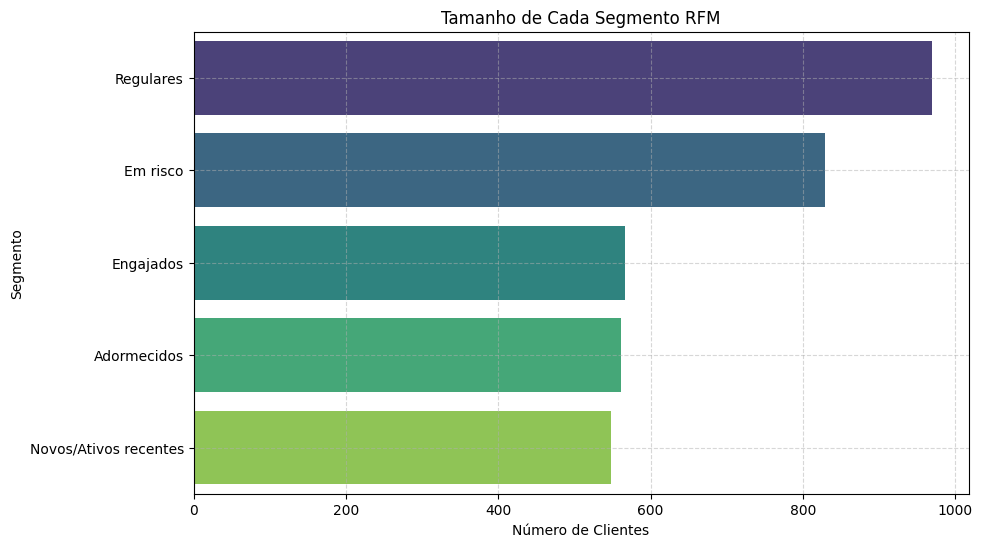

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preparando df_filtrado a partir do df carregado no notebook
# 1. Converter datas de string para datetime
df['data_extracao'] = pd.to_datetime(df['data_extracao'])
df['data_ultimo_acesso'] = pd.to_datetime(df['data_ultimo_acesso'])

# 2. Calcular a recencia (dias desde o último acesso)
df['recencia'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# Criando o df_filtrado solicitado
df_filtrado = df.copy()

# Filtrando o DataFrame para clientes ativos (churn == 0)
df_rfm = df_filtrado[df_filtrado['churn'] == 0].copy()

# Passo 1: Remover linhas onde 'recencia' seja nula
df_rfm = df_rfm.dropna(subset=['recencia'])

# Passo 2: Definir notas de 1 a 5 usando percentis para evitar erro de limites duplicados
# Usamos o ranking percentual para garantir a divisão correta em 5 grupos, mesmo com muitos valores idênticos

# Recência: Menor é melhor. Ao inverter o rank (1 - pct), menores valores ganham as maiores notas
df_rfm['R_pct'] = df_rfm['recencia'].rank(pct=True, method='first')
df_rfm['R'] = pd.cut(1 - df_rfm['R_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Frequência: Maior é melhor.
df_rfm['F_pct'] = df_rfm['dias_ativos_ult_mes'].rank(pct=True, method='first')
df_rfm['F'] = pd.cut(df_rfm['F_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Monetário: Maior é melhor.
df_rfm['M_pct'] = df_rfm['valor_mensal'].rank(pct=True, method='first')
df_rfm['M'] = pd.cut(df_rfm['M_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Mostrando os limites reais dos quantis teóricos para referência
print("--- Limites Teóricos dos Quintis ---")
print("Recência (Quintis):", df_rfm['recencia'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("Frequência (Quintis):", df_rfm['dias_ativos_ult_mes'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("Monetário (Quintis):", df_rfm['valor_mensal'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("\n")

# Passo 3: Criar código RFM concatenando as notas
df_rfm['RFM_score'] = 'R' + df_rfm['R'].astype(str) + 'F' + df_rfm['F'].astype(str) + 'M' + df_rfm['M'].astype(str)

# Passo 4: Classificar os clientes nos segmentos
def segmentar(row):
    r, f = row['R'], row['F']
    if r >= 4 and f >= 4:
        return 'Engajados'
    elif r <= 2 and f >= 3:
        return 'Em risco'
    elif r >= 4 and f <= 2:
        return 'Novos/Ativos recentes'
    elif r <= 2 and f <= 2:
        return 'Adormecidos'
    else:
        return 'Regulares'

df_rfm['segmento'] = df_rfm.apply(segmentar, axis=1)

# Passo 5: Contagem e porcentagem de clientes em cada segmento
contagem = df_rfm['segmento'].value_counts()
porcentagem = df_rfm['segmento'].value_counts(normalize=True) * 100

resumo_segmentos = pd.DataFrame({
    'Contagem': contagem,
    'Porcentagem (%)': porcentagem.round(2)
})
print("--- Distribuição dos Segmentos ---")
display(resumo_segmentos)

# Plotando o gráfico de barras horizontais
plt.figure(figsize=(10, 6))
sns.barplot(
    x=contagem.values,
    y=contagem.index,
    palette='viridis',
    hue=contagem.index,
    legend=False
)
plt.title('Tamanho de Cada Segmento RFM')
plt.xlabel('Número de Clientes')
plt.ylabel('Segmento')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

--- Limites dos Quintis ---
Recência (Quintis): {0.2: 6.0, 0.4: 11.0, 0.6: 17.0, 0.8: 23.0}
Frequência (Quintis): {0.2: 11.0, 0.4: 13.0, 0.6: 15.0, 0.8: 17.0}
Monetário (Quintis): {0.2: 19.9, 0.4: 34.9, 0.6: 34.9, 0.8: 55.9}


--- Distribuição dos Segmentos ---


,Contagem,Porcentagem (%)
segmento,,
Regulares,969,27.89
Em risco,829,23.86
Engajados,567,16.32
Adormecidos,561,16.15
Novos/Ativos recentes,548,15.77


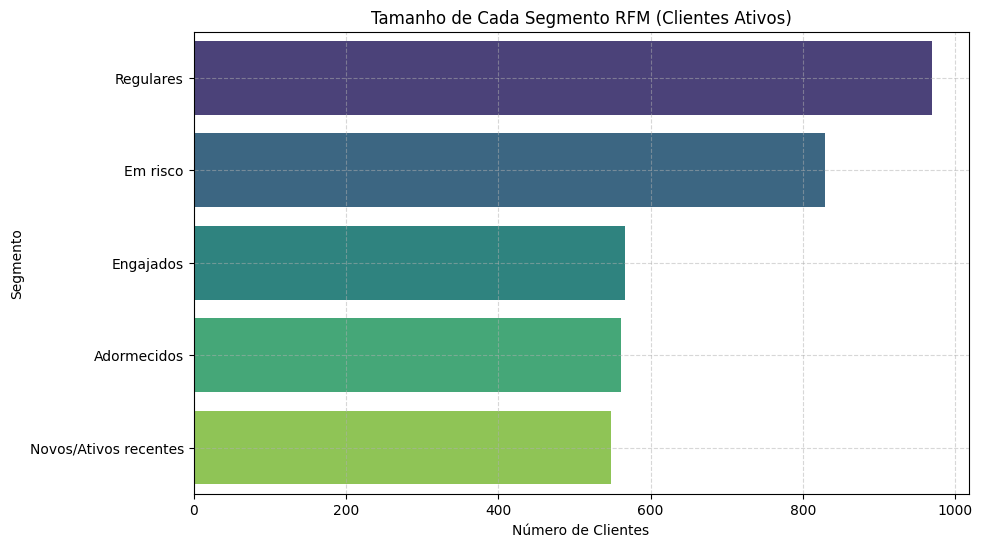

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Garantir que as colunas de data estejam no formato datetime e calcular a recência
df['data_extracao'] = pd.to_datetime(df['data_extracao'])
df['data_ultimo_acesso'] = pd.to_datetime(df['data_ultimo_acesso'])
df['recencia'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# Criando o df_filtrado solicitado (ativos, churn == 0)
df_filtrado = df.copy()
df_rfm = df_filtrado[df_filtrado['churn'] == 0].copy()

# Primeiro: Remover linhas onde a coluna recencia é nula
df_rfm = df_rfm.dropna(subset=['recencia'])

# Segundo: Definir notas de 1 a 5 usando percentis para evitar conflitos de valores idênticos
# Recência: Menor é melhor. Ao usar (1 - pct), os menores valores de recência recebem nota 5.
df_rfm['R_pct'] = df_rfm['recencia'].rank(pct=True, method='first')
df_rfm['R'] = pd.cut(1 - df_rfm['R_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Frequência: Maior é melhor.
df_rfm['F_pct'] = df_rfm['dias_ativos_ult_mes'].rank(pct=True, method='first')
df_rfm['F'] = pd.cut(df_rfm['F_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Monetário: Maior é melhor.
df_rfm['M_pct'] = df_rfm['valor_mensal'].rank(pct=True, method='first')
df_rfm['M'] = pd.cut(df_rfm['M_pct'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

# Mostrando os limites dos quintis reais de cada dimensão para conferência
print("--- Limites dos Quintis ---")
print("Recência (Quintis):", df_rfm['recencia'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("Frequência (Quintis):", df_rfm['dias_ativos_ult_mes'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("Monetário (Quintis):", df_rfm['valor_mensal'].quantile([0.2, 0.4, 0.6, 0.8]).to_dict())
print("\n")

# Terceiro: Criar código RFM concatenando as três notas
df_rfm['RFM_score'] = 'R' + df_rfm['R'].astype(str) + 'F' + df_rfm['F'].astype(str) + 'M' + df_rfm['M'].astype(str)

# Quarto: Classificar os clientes nos segmentos definidos
def segmentar(row):
    r, f = row['R'], row['F']
    if r >= 4 and f >= 4:
        return 'Engajados'
    elif r <= 2 and f >= 3:
        return 'Em risco'
    elif r >= 4 and f <= 2:
        return 'Novos/Ativos recentes'
    elif r <= 2 and f <= 2:
        return 'Adormecidos'
    else:
        return 'Regulares'

df_rfm['segmento'] = df_rfm.apply(segmentar, axis=1)

# Quinto: Mostrar contagem e porcentagem de cada segmento e plotar gráfico
contagem = df_rfm['segmento'].value_counts()
porcentagem = df_rfm['segmento'].value_counts(normalize=True) * 100

resumo_segmentos = pd.DataFrame({
    'Contagem': contagem,
    'Porcentagem (%)': porcentagem.round(2)
})
print("--- Distribuição dos Segmentos ---")
display(resumo_segmentos)

# Plotando gráfico de barras horizontais
plt.figure(figsize=(10, 6))
sns.barplot(
    x=contagem.values,
    y=contagem.index,
    palette='viridis',
    hue=contagem.index,
    legend=False
)
plt.title('Tamanho de Cada Segmento RFM (Clientes Ativos)')
plt.xlabel('Número de Clientes')
plt.ylabel('Segmento')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [22]:
import pandas as pd

# Agrupando os dados pelos segmentos para extrair as estatísticas de cada métrica original
perfil_segmentos = df_rfm.groupby('segmento').agg(
    Qtd_Clientes=('cliente_id', 'count'),

    Recencia_Min=('recencia', 'min'),
    Recencia_Media=('recencia', 'mean'),
    Recencia_Max=('recencia', 'max'),

    Dias_Ativos_Min=('dias_ativos_ult_mes', 'min'),
    Dias_Ativos_Medio=('dias_ativos_ult_mes', 'mean'),
    Dias_Ativos_Max=('dias_ativos_ult_mes', 'max'),

    Valor_Mensal_Min=('valor_mensal', 'min'),
    Valor_Mensal_Medio=('valor_mensal', 'mean'),
    Valor_Mensal_Max=('valor_mensal', 'max')
).round(2)

# Exibindo o perfil detalhado dos segmentos
display(perfil_segmentos)

,Qtd_Clientes,Recencia_Min,Recencia_Media,Recencia_Max,Dias_Ativos_Min,Dias_Ativos_Medio,Dias_Ativos_Max,Valor_Mensal_Min,Valor_Mensal_Medio,Valor_Mensal_Max
segmento,,,,,,,,,,
Adormecidos,561,17.0,23.33,29.0,3,10.43,13,19.9,393.51,5590.0
Em risco,829,17.0,23.43,29.0,13,16.24,27,19.9,400.67,5590.0
Engajados,567,0.0,5.69,11.0,15,17.62,26,19.9,456.20,5590.0
Novos/Ativos recentes,548,0.0,5.65,11.0,3,10.43,13,19.9,430.93,5590.0
Regulares,969,0.0,11.87,17.0,5,13.96,28,19.9,414.52,5590.0


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import unicodedata

# Função auxiliar para remover acentos e padronizar strings
def normalizar_texto(texto):
    if pd.isna(texto):
        return np.nan
    # Converte para minúsculas e remove espaços extras no início e fim
    texto = str(texto).strip().lower()
    # Normaliza e remove os caracteres de acentuação
    nfkd_form = unicodedata.normalize('NFKD', texto)
    return "".join([c for c in nfkd_form if not unicodedata.combining(c)])

# Criando uma cópia para trabalhar os cancelamentos sem afetar as análises anteriores
df_cancelados = df_filtrado.dropna(subset=['motivo_cancelamento']).copy()

# Aplicando a normalização sugerida
df_cancelados['motivo_normalizado'] = df_cancelados['motivo_cancelamento'].apply(normalizar_texto)

# 1. Contagem decrescente dos motivos de cancelamento
pareto_df = df_cancelados['motivo_normalizado'].value_counts().reset_index()
pareto_df.columns = ['Motivo', 'Quantidade']

# 2. Construindo as colunas de Porcentagem e Porcentagem Acumulada
total_cancelamentos = pareto_df['Quantidade'].sum()
pareto_df['Porcentagem (%)'] = (pareto_df['Quantidade'] / total_cancelamentos) * 100
pareto_df['Porcentagem Acumulada (%)'] = pareto_df['Porcentagem (%)'].cumsum()

print("--- Tabela de Pareto dos Motivos de Cancelamento ---")
display(pareto_df)

# 3. Identificando os motivos que representam aproximadamente 80% do total
# Selecionamos os motivos até o primeiro que ultrapassa ou se aproxima de 80%
limite_80 = 80.0
motivos_principais = pareto_df[pareto_df['Porcentagem Acumulada (%)'] - pareto_df['Porcentagem (%)'] < limite_80]

print("\n--- Motivos que concentram cerca de 80% dos cancelamentos ---")
for idx, row in motivos_principais.iterrows():
    print(f"- {row['Motivo'].upper()}: {row['Quantidade']} cancelamentos ({row['Porcentagem (%)']:.2f}% do total, acumulado: {row['Porcentagem Acumulada (%)']:.2f}%)")

--- Tabela de Pareto dos Motivos de Cancelamento ---


,Motivo,Quantidade,Porcentagem (%),Porcentagem Acumulada (%)
0,preco,510,33.641161,33.641161
1,pouco conteudo novo,385,25.395778,59.036939
2,problema tecnico,250,16.490765,75.527704
3,falta de tempo,174,11.477573,87.005277
4,concorrente,130,8.575198,95.580475
5,outro,67,4.419525,100.000000



--- Motivos que concentram cerca de 80% dos cancelamentos ---
- PRECO: 510 cancelamentos (33.64% do total, acumulado: 33.64%)
- POUCO CONTEUDO NOVO: 385 cancelamentos (25.40% do total, acumulado: 59.04%)
- PROBLEMA TECNICO: 250 cancelamentos (16.49% do total, acumulado: 75.53%)
- FALTA DE TEMPO: 174 cancelamentos (11.48% do total, acumulado: 87.01%)


/tmp/ipykernel_5739/1762317675.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(pareto_df['Motivo'], rotation=45, ha='right')


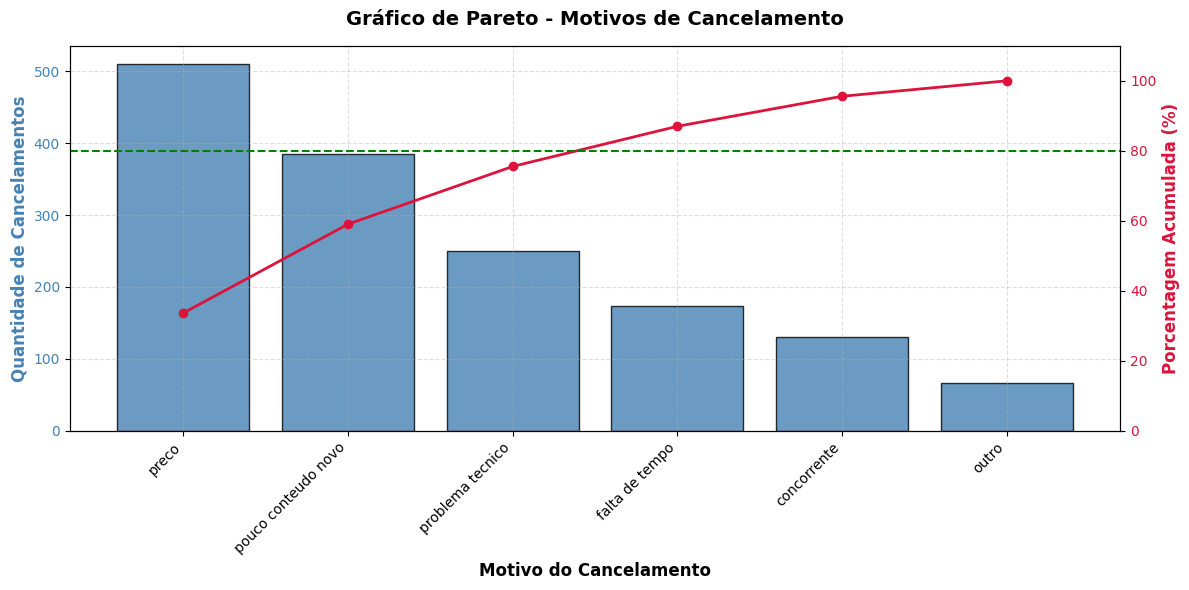

In [24]:
# 4. Plotagem do Gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))

# Gráfico de Barras para a Quantidade (Eixo Y esquerdo)
color_bar = 'steelblue'
ax1.bar(pareto_df['Motivo'], pareto_df['Quantidade'], color=color_bar, alpha=0.8, edgecolor='black')
ax1.set_xlabel('Motivo do Cancelamento', fontsize=12, fontweight='bold')
ax1.set_ylabel('Quantidade de Cancelamentos', color=color_bar, fontsize=12, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color_bar)
ax1.set_xticklabels(pareto_df['Motivo'], rotation=45, ha='right')

# Criando o segundo eixo Y compartilhado para a Porcentagem Acumulada
ax2 = ax1.twinx()
color_line = 'crimson'
ax2.plot(pareto_df['Motivo'], pareto_df['Porcentagem Acumulada (%)'], color=color_line, marker='o', linewidth=2, label='Acumulado (%)')
ax2.set_ylabel('Porcentagem Acumulada (%)', color=color_line, fontsize=12, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color_line)
ax2.set_ylim(0, 110)

# Adicionando a linha horizontal de referência em 80%
ax2.axhline(y=80, color='green', linestyle='--', linewidth=1.5, label='Limite 80%')

plt.title('Gráfico de Pareto - Motivos de Cancelamento', fontsize=14, fontweight='bold', pad=15)
ax1.grid(True, linestyle='--', alpha=0.4)
fig.tight_layout()
plt.show()

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Importação e normalização dos dados do Funil
df_funil = pd.read_csv('/content/funil_eventos.csv')

# Padronizar a escrita da coluna etapa
df_funil['etapa'] = df_funil['etapa'].str.strip().str.lower().str.replace(' ', '_')

# Ordem correta das etapas do funil
ordem_funil = ['visitou_site', 'criou_conta', 'assistiu_1a_aula', 'assinou_plano', 'renovou']

# 2. Contar quantos clientes únicos alcançaram cada etapa
usuarios_etapa = []
for etapa in ordem_funil:
    # Filtrando e obtendo quantidade de usuários únicos que passaram por esta etapa
    qtd_unicos = df_funil[df_funil['etapa'] == etapa]['cliente_id'].nunique()
    usuarios_etapa.append(qtd_unicos)

# Criando o DataFrame base para calcular as conversões
tabela_funil = pd.DataFrame({
    'Etapa': ordem_funil,
    'Usuarios': usuarios_etapa
})

# 3. Calculando as taxas de conversão
taxa_anterior = [100.0]  # A primeira etapa sempre começa em 100%
topo_funil = tabela_funil.loc[0, 'Usuarios']

for i in range(1, len(tabela_funil)):
    anterior = tabela_funil.loc[i-1, 'Usuarios']
    atual = tabela_funil.loc[i, 'Usuarios']
    taxa_anterior.append((atual / anterior) * 100 if anterior > 0 else 0.0)

tabela_funil['Conversao_Anterior (%)'] = round(pd.Series(taxa_anterior), 2)
tabela_funil['Conversao_Topo (%)'] = round((tabela_funil['Usuarios'] / topo_funil) * 100, 2)

# 4. Identificando a etapa com a maior queda de conversão (gargalo)
# O gargalo é onde a taxa em relação à etapa anterior é a menor (ou seja, onde perdemos mais clientes percentualmente)
tabela_funil['Queda (%)'] = 100 - tabela_funil['Conversao_Anterior (%)']
# Desconsideramos a primeira linha (pois não tem etapa anterior)
etapa_gargalo_idx = tabela_funil.loc[1:, 'Conversao_Anterior (%)'].idxmin()
etapa_gargalo = tabela_funil.loc[etapa_gargalo_idx, 'Etapa']
perda_gargalo = tabela_funil.loc[etapa_gargalo_idx, 'Queda (%)']

print("--- TABELA DE FUNIL DE CONVERSÃO ---")
display(tabela_funil[['Etapa', 'Usuarios', 'Conversao_Anterior (%)', 'Conversao_Topo (%)']])
print(f"\nO maior gargalo do funil está na transição para a etapa: {etapa_gargalo.upper()} (Queda de {perda_gargalo:.2f}% dos usuários que estavam na etapa anterior).")

--- TABELA DE FUNIL DE CONVERSÃO ---


,Etapa,Usuarios,Conversao_Anterior (%),Conversao_Topo (%)
0,visitou_site,5000,100.00,100.00
1,criou_conta,3377,67.54,67.54
2,assistiu_1a_aula,2698,79.89,53.96
3,assinou_plano,1066,39.51,21.32
4,renovou,695,65.20,13.90



O maior gargalo do funil está na transição para a etapa: ASSINOU_PLANO (Queda de 60.49% dos usuários que estavam na etapa anterior).


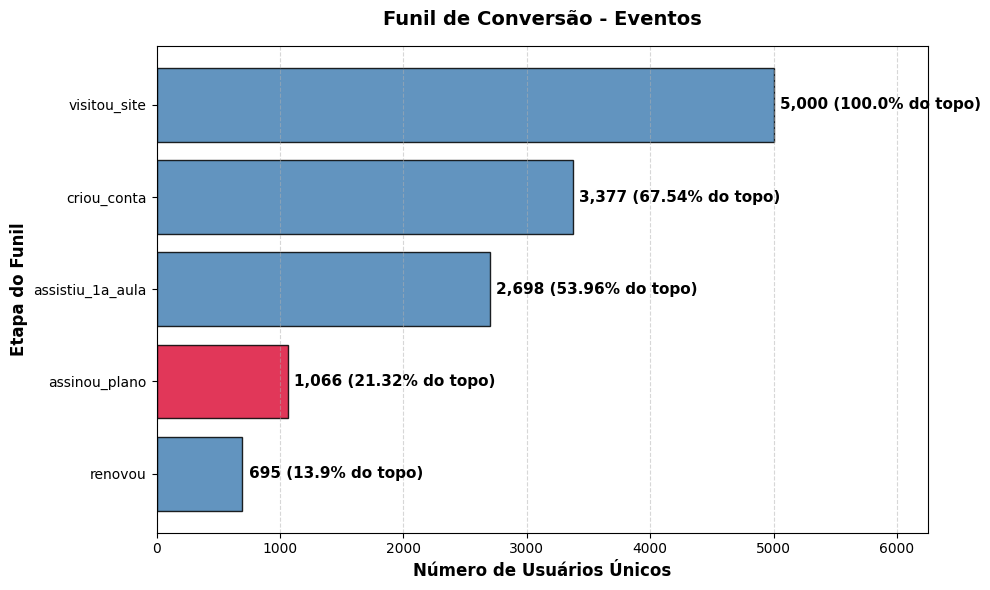

In [26]:
# 5. Plotando o funil como gráfico de barras horizontais
plt.figure(figsize=(10, 6))

# Definindo as cores: cor diferente de destaque para a etapa gargalo
cores = ['crimson' if etapa == etapa_gargalo else 'steelblue' for etapa in tabela_funil['Etapa']]

# Inverter a ordem para que o topo do funil ('visitou_site') apareça no topo do gráfico de barras horizontais
tabela_plot = tabela_funil.iloc[::-1].copy()
cores_plot = cores[::-1]

plt.barh(tabela_plot['Etapa'], tabela_plot['Usuarios'], color=cores_plot, edgecolor='black', alpha=0.85)

# Adicionando rótulos com a quantidade e a taxa acumulada do topo em cada barra
for index, value in enumerate(tabela_plot['Usuarios']):
    taxa_topo = tabela_plot.iloc[index]['Conversao_Topo (%)']
    plt.text(value + (topo_funil * 0.01), index, f"{value:,} ({taxa_topo}% do topo)",
             va='center', fontsize=11, fontweight='bold')

plt.title('Funil de Conversão - Eventos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Usuários Únicos', fontsize=12, fontweight='bold')
plt.ylabel('Etapa do Funil', fontsize=12, fontweight='bold')
plt.xlim(0, topo_funil * 1.25)  # Dar espaço para os rótulos de texto à direita
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()